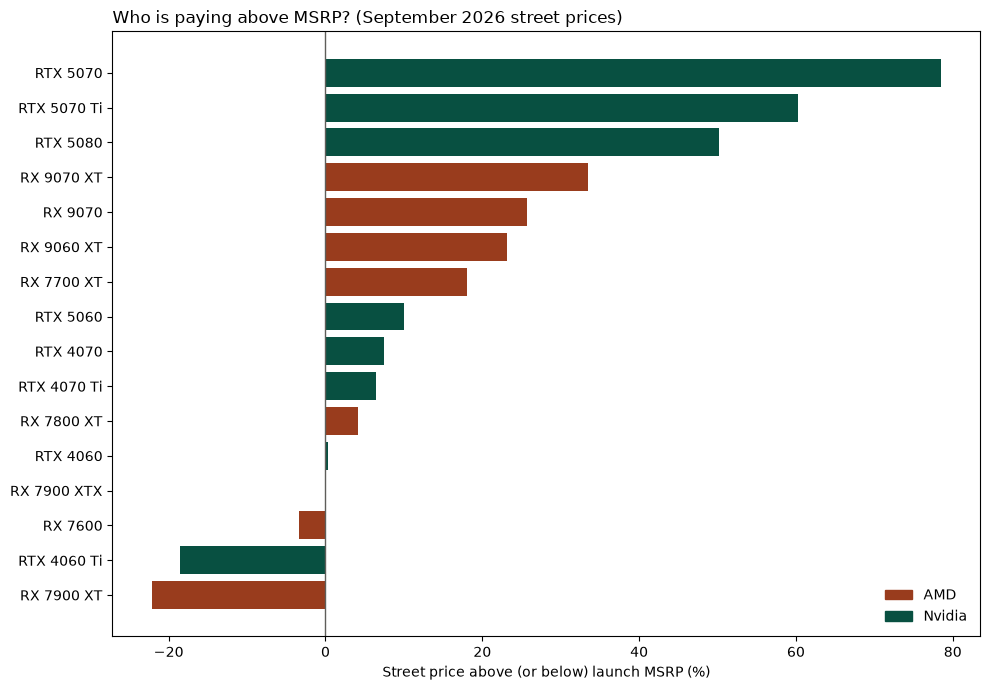

count  mean
Generation Brand              
2022-24    AMD         5  -1.0
           Nvidia      4  -1.0
2025-26    AMD         3  27.0
           Nvidia      4  50.0

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

hw = pd.read_csv('hardware_data.csv')
hw = hw[hw['Full_Model_Name'] != 'GeForce RTX 2060 Super']

hw['Premium_vs_MSRP_Pct'] = ((hw['Current_Street_Price'] / hw['MSRP_Price']) - 1) * 100

table = hw[['Full_Model_Name', 'Brand', 'MSRP_Price', 'Current_Street_Price', 'Premium_vs_MSRP_Pct']]
table.sort_values('Premium_vs_MSRP_Pct', ascending=False).round(0)

d = hw.sort_values('Premium_vs_MSRP_Pct')
names = d['Full_Model_Name'].str.replace('GeForce ', '').str.replace('Radeon ', '')
colors = d['Brand'].map({'AMD': '#993C1D', 'Nvidia': '#085041'})

plt.figure(figsize=(10, 7))
plt.barh(names, d['Premium_vs_MSRP_Pct'], color=colors)
plt.axvline(0, color='#5f5e5a', linewidth=1)
plt.xlabel('Street price above (or below) launch MSRP (%)')
plt.title('Who is paying above MSRP? (September 2026 street prices)', loc='left')
plt.legend(handles=[Patch(color='#993C1D', label='AMD'), Patch(color='#085041', label='Nvidia')],
           frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

hw['Generation'] = hw['Series_Generation'].apply(lambda s: '2025-26' if s in (50, 90) else '2022-24')
hw.groupby(['Generation', 'Brand'])['Premium_vs_MSRP_Pct'].agg(['count', 'mean']).round(0)